# AOD-Net: NHD Training and RESIDE / RESIDE-6K Testing

A Kaggle-ready original AOD-Net implementation with the same NHD training and paired NHD/RESIDE/RESIDE-6K evaluation workflow.

## Setup Dependencies


In [1]:
%%capture
!pip -q install scikit-image --root-user-action=ignore

## Imports and Warning Control


In [2]:
import os
# Set before CUDA/PyTorch initialization; restart the Kaggle kernel, then Run All.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import json
import random
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## Configuration
Update only the dataset paths if your Kaggle input slugs differ. The required folder layout is unchanged from `nhdv2`.


In [3]:
@dataclass
class CFG:
    ROOT: str = "/kaggle/input/datasets/mouryavardhanrathod/nhd-dataset-v1/NHD"
    INDEX_FILE: str = ""
    RESIDE_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD/test"
    RESIDE6K_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset/test"

    IMAGE_SIZE: int = 256
    BATCH_SIZE: int = 16
    ACCUM_STEPS: int = 1
    EPOCHS: int = 100
    LR: float = 2e-4
    WEIGHT_DECAY: float = 1e-4
    PATIENCE: int = 12
    NUM_WORKERS: int = 2
    SEED: int = 42
    OUT_DIR: str = "/kaggle/working/aodnet_nhd"
    SELECTED_STRATEGIES: tuple = ("uniform", "fog_bank", "perlin", "radial", "depth_dep")

cfg = CFG()
cfg.INDEX_FILE = os.path.join(cfg.ROOT, "dataset_index.json")
os.makedirs(cfg.OUT_DIR, exist_ok=True)
print("Output dir:", cfg.OUT_DIR)

Output dir: /kaggle/working/aodnet_nhd


## NHD Dataset Loader
NHD training/validation/test splits come from `dataset_index.json`. RESIDE and reside-6k use paired image folders for external evaluation.


In [4]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
image_transform = transforms.Compose([
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
])

def list_images(folder):
    if not folder or not os.path.isdir(folder):
        return []
    return sorted(
        os.path.join(root, name)
        for root, _, files in os.walk(folder)
        for name in files
        if name.lower().endswith(IMAGE_EXTENSIONS)
    )

def normalize_pair_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    for token in ("_hazy", "-hazy", " haze", "_gt", "-gt", "_clean", "-clean", "_clear", "-clear"):
        stem = stem.replace(token, "")
    return stem

def build_image_pairs_from_folders(hazy_dir, gt_dir):
    hazy_paths, gt_paths = list_images(hazy_dir), list_images(gt_dir)
    gt_by_stem = {normalize_pair_stem(path): path for path in gt_paths}
    pairs = [(hazy, gt_by_stem[normalize_pair_stem(hazy)]) for hazy in hazy_paths if normalize_pair_stem(hazy) in gt_by_stem]
    return pairs or (list(zip(hazy_paths, gt_paths)) if len(hazy_paths) == len(gt_paths) else [])

def find_paired_root(preferred, alternatives):
    for root in (preferred, *alternatives):
        if os.path.isdir(os.path.join(root, "hazy")) and os.path.isdir(os.path.join(root, "gt")):
            return root
    return None

class PairedDehazeDataset(Dataset):
    def __init__(self, pairs, dataset_name):
        self.pairs, self.dataset_name = pairs, dataset_name

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        hazy_path, gt_path = self.pairs[idx]
        hazy = Image.open(hazy_path).convert("RGB")
        gt = Image.open(gt_path).convert("RGB")
        return {
            "hazy": image_transform(hazy),
            "gt": image_transform(gt),
            "dataset": self.dataset_name,
            "img_id": os.path.basename(hazy_path),
        }

def build_nhd_pairs(split):
    if not os.path.isfile(cfg.INDEX_FILE):
        raise FileNotFoundError(f"NHD index not found: {cfg.INDEX_FILE}")
    with open(cfg.INDEX_FILE, "r") as f:
        metadata = json.load(f)
    pairs = []
    for item in metadata:
        if item.get("split") != split or item.get("strategy") not in cfg.SELECTED_STRATEGIES:
            continue
        hazy = os.path.join(cfg.ROOT, item["hazy_path"])
        gt = os.path.join(cfg.ROOT, item["gt_path"])
        if os.path.isfile(hazy) and os.path.isfile(gt):
            pairs.append((hazy, gt))
    return pairs

train_dataset = PairedDehazeDataset(build_nhd_pairs("train"), "NHD_dataset")
val_dataset = PairedDehazeDataset(build_nhd_pairs("val"), "NHD_dataset")
test_dataset = PairedDehazeDataset(build_nhd_pairs("test"), "NHD_dataset")
assert len(train_dataset) and len(val_dataset) and len(test_dataset), "NHD split is empty; check cfg.ROOT."

def make_loader(dataset, shuffle=False):
    return DataLoader(dataset, batch_size=cfg.BATCH_SIZE, shuffle=shuffle, num_workers=cfg.NUM_WORKERS, pin_memory=torch.cuda.is_available())

train_loader, val_loader, test_loader = make_loader(train_dataset, True), make_loader(val_dataset), make_loader(test_dataset)
print(f"NHD pairs — train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")


NHD pairs — train: 560, val: 70, test: 70


## Original AOD-Net Architecture

AOD-Net estimates a unified per-pixel function \(K(x)\), instead of separately predicting atmospheric light and transmission. Its five original convolutional stages use dense feature concatenation: 1×1, 3×3, 5×5 from the first two stages, 7×7 from the middle stages, then a final 3×3 prediction. The dehazed image is computed by the paper’s all-in-one equation \(J(x)=K(x)I(x)-K(x)+1\).

In [5]:
class AODNet(nn.Module):
    """Original AOD-Net (Li et al., ICCV 2017)."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 3, kernel_size=1)
        self.conv2 = nn.Conv2d(3, 3, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(6, 3, kernel_size=5, padding=2)
        self.conv4 = nn.Conv2d(6, 3, kernel_size=7, padding=3)
        self.conv5 = nn.Conv2d(12, 3, kernel_size=3, padding=1)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, hazy):
        x1 = self.relu(self.conv1(hazy))
        x2 = self.relu(self.conv2(x1))
        x3 = self.relu(self.conv3(torch.cat([x1, x2], dim=1)))
        x4 = self.relu(self.conv4(torch.cat([x2, x3], dim=1)))
        k_map = self.relu(self.conv5(torch.cat([x1, x2, x3, x4], dim=1)))
        # AOD-Net's original all-in-one atmospheric-scattering re-formulation.
        return k_map * hazy - k_map + 1.0


model = AODNet().to(device)
print(model)
print(f'AOD-Net trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

AODNet(
  (conv1): Conv2d(3, 3, kernel_size=(1, 1), stride=(1, 1))
  (conv2): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(6, 3, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv4): Conv2d(6, 3, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
  (conv5): Conv2d(12, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU(inplace=True)
)
AOD-Net trainable parameters: 1,761


## End-to-End Joint Training
Train AOD-Net directly on NHD paired hazy/clean images. The checkpoint with the highest validation PSNR is retained.


In [6]:
def charbonnier_loss(pred, target, eps=1e-3):
    return torch.mean(torch.sqrt((pred - target).pow(2) + eps * eps))

def batch_psnr(pred, target, eps=1e-8):
    mse = (pred - target).pow(2).flatten(1).mean(1).clamp_min(eps)
    return (10.0 * torch.log10(1.0 / mse)).mean()

def batch_ssim(pred, target, eps=1e-8):
    """Dependency-free global SSIM for training diagnostics (higher is better)."""
    x, y = pred.flatten(1), target.flatten(1)
    mux, muy = x.mean(1), y.mean(1)
    vx, vy = x.var(1, unbiased=False), y.var(1, unbiased=False)
    cov = ((x - mux[:, None]) * (y - muy[:, None])).mean(1)
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    score = ((2 * mux * muy + c1) * (2 * cov + c2)) / ((mux.square() + muy.square() + c1) * (vx + vy + c2) + eps)
    return score.mean()

def loss_fn(pred, target):
    return charbonnier_loss(pred, target)

def evaluate(model, loader):
    model.eval(); losses, psnrs, ssims, maes = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            hazy = batch['hazy'].to(device, non_blocking=True)
            gt = batch['gt'].to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=amp_enabled):
                pred = model(hazy); loss = loss_fn(pred, gt)
            pred, gt = pred.float(), gt.float()
            losses.append(loss.float().item()); psnrs.append(batch_psnr(pred, gt).item()); ssims.append(batch_ssim(pred, gt).item()); maes.append(F.l1_loss(pred, gt).item())
    return {'loss': float(np.mean(losses)), 'psnr': float(np.mean(psnrs)), 'ssim': float(np.mean(ssims)), 'mae': float(np.mean(maes))}

amp_enabled = device.type == 'cuda'
scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)
history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_psnr': [], 'val_ssim': [], 'val_mae': []}
best_psnr, bad_epochs = -float('inf'), 0
checkpoint_path = os.path.join(cfg.OUT_DIR, 'best_aodnet_nhd.pth')

for epoch in range(cfg.EPOCHS):
    model.train(); train_losses = []; optimizer.zero_grad(set_to_none=True)
    for step, batch in enumerate(tqdm(train_loader, desc=f'Epoch {epoch + 1}/{cfg.EPOCHS}', leave=False), start=1):
        hazy = batch['hazy'].to(device, non_blocking=True); gt = batch['gt'].to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=amp_enabled):
            loss = loss_fn(model(hazy), gt)
        scaler.scale(loss / cfg.ACCUM_STEPS).backward(); train_losses.append(loss.float().item())
        if step % cfg.ACCUM_STEPS == 0 or step == len(train_loader):
            scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
    val = evaluate(model, val_loader); train_loss = float(np.mean(train_losses))
    history['epoch'].append(epoch + 1); history['train_loss'].append(train_loss); history['val_loss'].append(val['loss']); history['val_psnr'].append(val['psnr']); history['val_ssim'].append(val['ssim']); history['val_mae'].append(val['mae'])
    scheduler.step(val['psnr'])
    print(f"Epoch {epoch + 1:03d} | train={train_loss:.5f} | val_loss={val['loss']:.5f} | val_psnr={val['psnr']:.2f} | val_ssim={val['ssim']:.4f} | val_mae={val['mae']:.5f}")
    if val['psnr'] > best_psnr:
        best_psnr, bad_epochs = val['psnr'], 0; torch.save(model.state_dict(), checkpoint_path)
    else:
        bad_epochs += 1
        if bad_epochs >= cfg.PATIENCE:
            print('Early stopping.'); break

model.load_state_dict(torch.load(checkpoint_path, map_location=device))
print('Best validation PSNR:', f'{best_psnr:.2f}', '| checkpoint:', checkpoint_path)

Epoch 1/100:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 001 | train=0.58794 | val_loss=0.55987 | val_psnr=4.52 | val_ssim=0.0430 | val_mae=0.55987


Epoch 2/100:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 002 | train=0.48515 | val_loss=0.34431 | val_psnr=8.27 | val_ssim=0.2610 | val_mae=0.34430


Epoch 3/100:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 003 | train=0.21523 | val_loss=0.13493 | val_psnr=15.92 | val_ssim=0.6228 | val_mae=0.13491


... (124 outputs left out)

Epoch 61/100:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 061 | train=0.11896 | val_loss=0.11138 | val_psnr=17.70 | val_ssim=0.7559 | val_mae=0.11136


Epoch 62/100:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 062 | train=0.11897 | val_loss=0.11179 | val_psnr=17.69 | val_ssim=0.7547 | val_mae=0.11177
Early stopping.
Best validation PSNR: 17.72 | checkpoint: /kaggle/working/aodnet_nhd/best_aodnet_nhd.pth


## Training Curves
Training Loss Curve, Validation Metric Curve, and MAE vs Epoch.


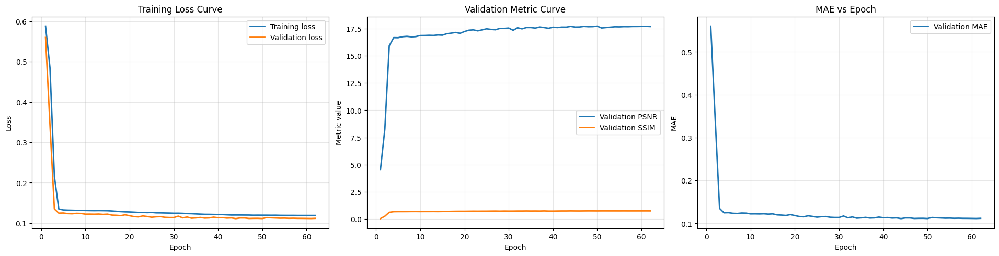

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)
epochs = history["epoch"]
axes[0].plot(epochs, history["train_loss"], label="Training loss", linewidth=2)
axes[0].plot(epochs, history["val_loss"], label="Validation loss", linewidth=2)
axes[0].set(title="Training Loss Curve", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=.3); axes[0].legend()
axes[1].plot(epochs, history["val_psnr"], label="Validation PSNR", linewidth=2)
axes[1].plot(epochs, history["val_ssim"], label="Validation SSIM", linewidth=2)
axes[1].set(title="Validation Metric Curve", xlabel="Epoch", ylabel="Metric value")
axes[1].grid(alpha=.3); axes[1].legend()
axes[2].plot(epochs, history["val_mae"], label="Validation MAE", linewidth=2)
axes[2].set(title="MAE vs Epoch", xlabel="Epoch", ylabel="MAE")
axes[2].grid(alpha=.3); axes[2].legend()
plt.show()


## Test Protocol: NHD, RESIDE, and reside-6k
Every paired hazy image is dehazed and compared with its ground truth using PSNR, SSIM, MAE, and RMSE.


In [8]:
def dehaze_metrics(pred, gt):
    return {
        "PSNR": float(peak_signal_noise_ratio(gt, pred, data_range=1.0)),
        "SSIM": float(structural_similarity(gt, pred, channel_axis=-1, data_range=1.0)),
        "MAE": float(np.abs(pred.astype(np.float32) - gt.astype(np.float32)).mean()),
        "RMSE": float(np.sqrt(np.mean((pred.astype(np.float32) - gt.astype(np.float32)) ** 2))),
    }

def evaluate_dataset(model, dataset):
    records = []
    loader = make_loader(dataset)
    model.eval()
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Test {dataset.dataset_name}"):
            pred = model(batch["hazy"].to(device)).cpu()
            for i in range(pred.shape[0]):
                pred_np = pred[i].permute(1, 2, 0).numpy()
                gt_np = batch["gt"][i].permute(1, 2, 0).numpy()
                scores = dehaze_metrics(pred_np, gt_np)
                records.append({"dataset": dataset.dataset_name, "img_id": batch["img_id"][i], **scores})
    return pd.DataFrame(records)

reside_root = find_paired_root(cfg.RESIDE_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD",
    "/kaggle/input/reside-dataset-1/RESIDE_NHD/test",
    "/kaggle/input/reside/RESIDE_NHD/test",
])
reside6k_root = find_paired_root(cfg.RESIDE6K_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset",
    "/kaggle/input/reside-6k-dataset/test",
    "/kaggle/input/reside6k-dataset/test",
])

test_datasets = {"NHD_dataset": test_dataset}
if reside_root:
    reside_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside_root, "hazy"), os.path.join(reside_root, "gt")), "RESIDE")
    if len(reside_dataset): test_datasets["RESIDE"] = reside_dataset
else:
    print("RESIDE not found; attach the dataset or update cfg.RESIDE_ROOT.")
if reside6k_root:
    reside6k_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside6k_root, "hazy"), os.path.join(reside6k_root, "gt")), "reside-6k")
    if len(reside6k_dataset): test_datasets["reside-6k"] = reside6k_dataset
else:
    print("reside-6k not found; attach the dataset or update cfg.RESIDE6K_ROOT.")

per_image_results = pd.concat([evaluate_dataset(model, ds) for ds in test_datasets.values()], ignore_index=True)
dataset_summary = per_image_results.groupby("dataset", as_index=False).agg(Images=("img_id", "count"), PSNR=("PSNR", "mean"), SSIM=("SSIM", "mean"), MAE=("MAE", "mean"), RMSE=("RMSE", "mean")).sort_values("dataset")
display(dataset_summary.style.format({"PSNR": "{:.4f}", "SSIM": "{:.4f}", "MAE": "{:.6f}", "RMSE": "{:.6f}"}))
per_image_results.to_csv(os.path.join(cfg.OUT_DIR, "aodnet_per_image_results.csv"), index=False)
dataset_summary.to_csv(os.path.join(cfg.OUT_DIR, "aodnet_dataset_summary.csv"), index=False)


Test NHD_dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Test RESIDE:   0%|          | 0/13 [00:00<?, ?it/s]

Test reside-6k:   0%|          | 0/63 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ee4143d80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e2ee4143d80>^^^
Traceback (most recent call last):
^^^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
^    
self._shutdown_workers()  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
if w.is_alive(): 
            ^^ ^^ ^^ ^ ^ ^^^^^^^^
^  File 

,dataset,Images,PSNR,SSIM,MAE,RMSE
0,NHD_dataset,70,16.6389,0.7595,0.128863,0.156610
1,RESIDE,200,20.5372,0.8893,0.079128,0.097780
2,reside-6k,1000,19.3395,0.8241,0.093170,0.115310


## PSNR Comparison


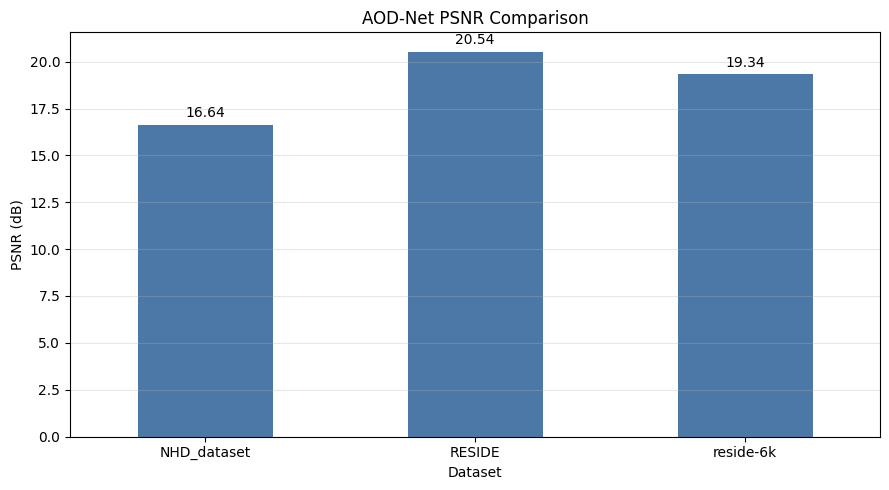

In [9]:
ax = dataset_summary.plot(x="dataset", y="PSNR", kind="bar", legend=False, figsize=(9, 5), color="#4C78A8")
ax.set(title="AOD-Net PSNR Comparison", xlabel="Dataset", ylabel="PSNR (dB)")
ax.set_xticklabels(dataset_summary["dataset"], rotation=0)
ax.grid(axis="y", alpha=.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.tight_layout(); plt.show()


## Subjective Visual Comparison
Show input haze, ground truth, AOD-Net output, and an absolute-error map for every test dataset.


NHD_dataset


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.2536149..0.9560119].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.37625468..0.9369164].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.17259455..0.8503368].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.26211286..0.867278].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.050249815..0.9592197].


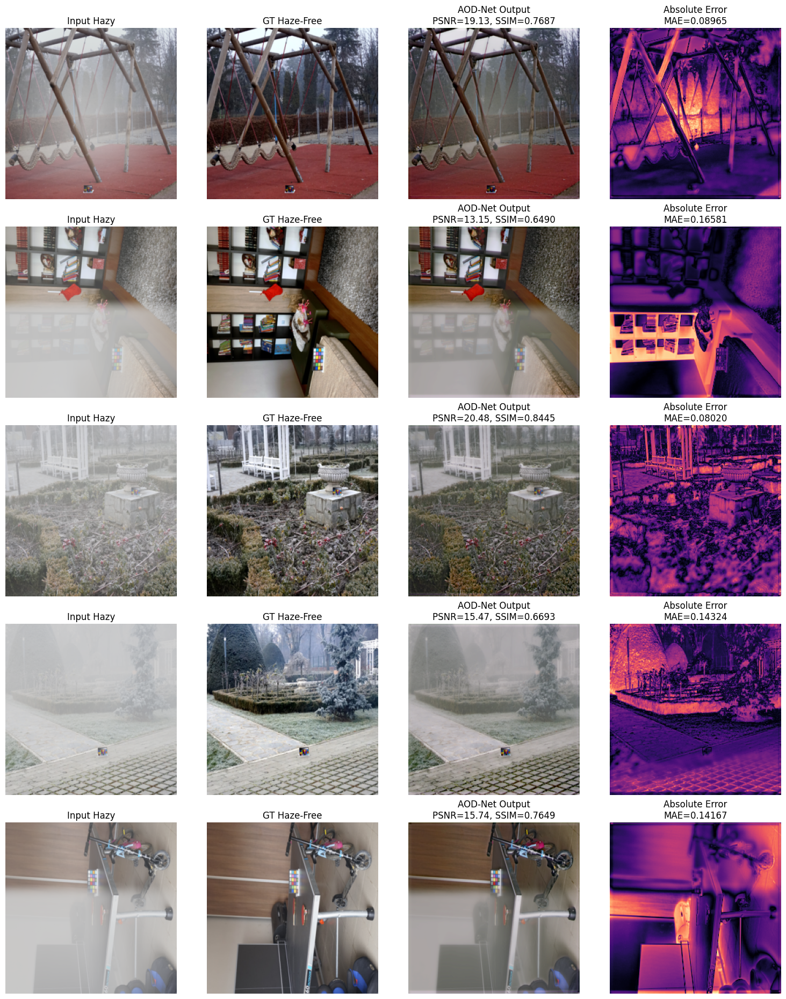

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.056117058..0.96696234].


RESIDE


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.15058613..0.9932934].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.072052956..0.96215844].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.18534541..0.9164194].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.2071613..0.9882402].


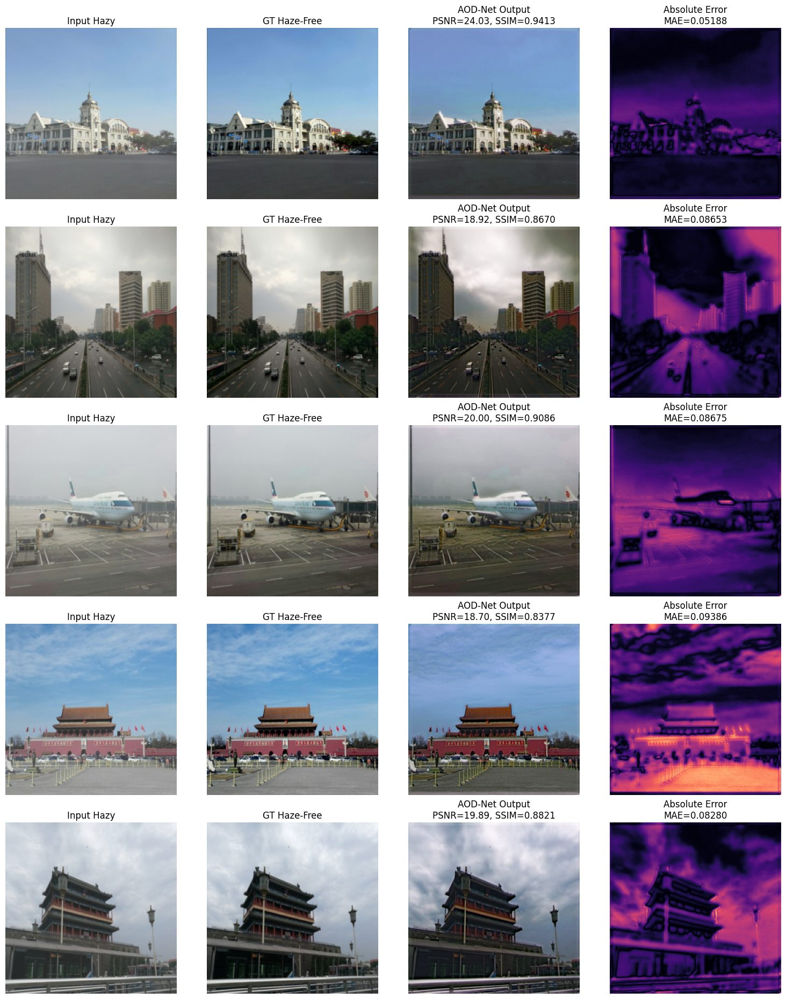

reside-6k


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.36279798..0.9908866].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.21092784..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.27702546..0.9851463].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.17165613..0.974206].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.04930854..1.0].


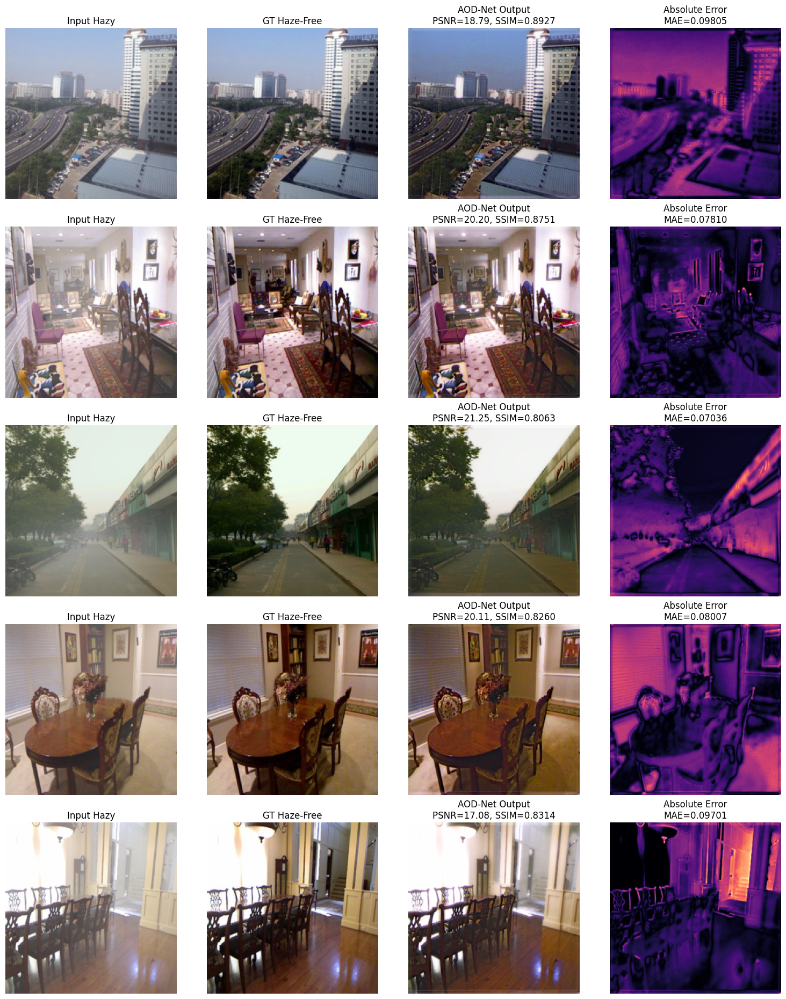

In [10]:
def show_subjective_comparison(model, dataset, n=5):
    model.eval()
    indices = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(len(indices), 4, figsize=(15, 3.7 * len(indices)), constrained_layout=True)
    if len(indices) == 1: axes = axes[None, :]
    with torch.no_grad():
        for row, idx in enumerate(indices):
            item = dataset[idx]
            hazy, gt = item["hazy"], item["gt"]
            pred = model(hazy.unsqueeze(0).to(device)).squeeze(0).cpu()
            hazy_np, gt_np, pred_np = [x.permute(1, 2, 0).numpy() for x in (hazy, gt, pred)]
            scores = dehaze_metrics(pred_np, gt_np)
            panels = [(hazy_np, "Input Hazy"), (gt_np, "GT Haze-Free"), (pred_np, f"AOD-Net Output\nPSNR={scores['PSNR']:.2f}, SSIM={scores['SSIM']:.4f}"), (np.abs(pred_np - gt_np).mean(-1), f"Absolute Error\nMAE={scores['MAE']:.5f}")]
            for col, (image, title) in enumerate(panels):
                axes[row, col].imshow(image, cmap="magma" if col == 3 else None)
                axes[row, col].set_title(title); axes[row, col].axis("off")
    plt.show()

for name, dataset in test_datasets.items():
    print(name)
    show_subjective_comparison(model, dataset, n=5)


## Model Summary and Presentation Export


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.052790403..0.85920143].


Model: AODNet
Trainable parameters: 1,761


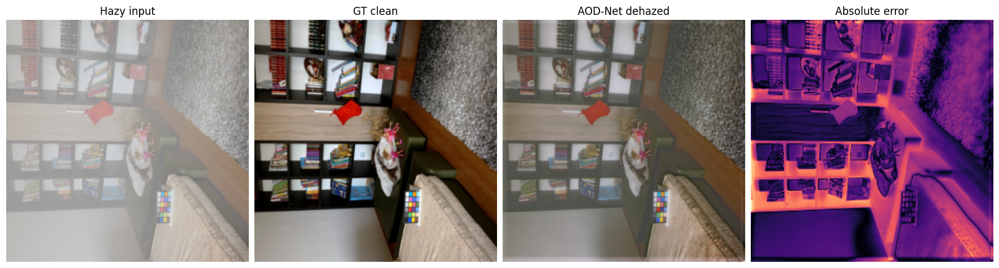

Saved: /kaggle/working/aodnet_nhd/aodnet_NHD_dataset_sample_000.png


,PSNR,SSIM,MAE,RMSE
0,16.5412,0.7276,0.1272,0.1489


In [11]:
def export_presentation_sample(model, dataset, sample_index=0, output_dir=None):
    output_dir = output_dir or cfg.OUT_DIR
    os.makedirs(output_dir, exist_ok=True)
    item = dataset[sample_index]
    model.eval()
    with torch.no_grad():
        pred = model(item["hazy"].unsqueeze(0).to(device)).squeeze(0).cpu()
    hazy, gt, pred = [x.permute(1, 2, 0).numpy() for x in (item["hazy"], item["gt"], pred)]
    error = np.abs(pred - gt).mean(-1)
    scores = dehaze_metrics(pred, gt)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), constrained_layout=True)
    for ax, image, title in zip(axes, [hazy, gt, pred, error], ["Hazy input", "GT clean", "AOD-Net dehazed", "Absolute error"]):
        ax.imshow(image, cmap="magma" if title == "Absolute error" else None)
        ax.set_title(title); ax.axis("off")
    path = os.path.join(output_dir, f"aodnet_{dataset.dataset_name}_sample_{sample_index:03d}.png")
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path)
    display(pd.DataFrame([scores]).round(4))
    return path, scores

print(f"Model: {model.__class__.__name__}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
presentation_panel_path, presentation_sample_metrics = export_presentation_sample(model, test_dataset, sample_index=0)